# Deep Variant Impact Mapping (DVIM) Tutorial

Welcome to the tutorial for DVIM with DNACipher, which calls variants with significant predicted effects
at GWAS loci ('impact variants') that are ABOVE background variants confidently un-associated with the trait.

This tutorial will focus on the RUNX3 GWAS locus for Type 1 Diabetes, to regenerate the below figure:
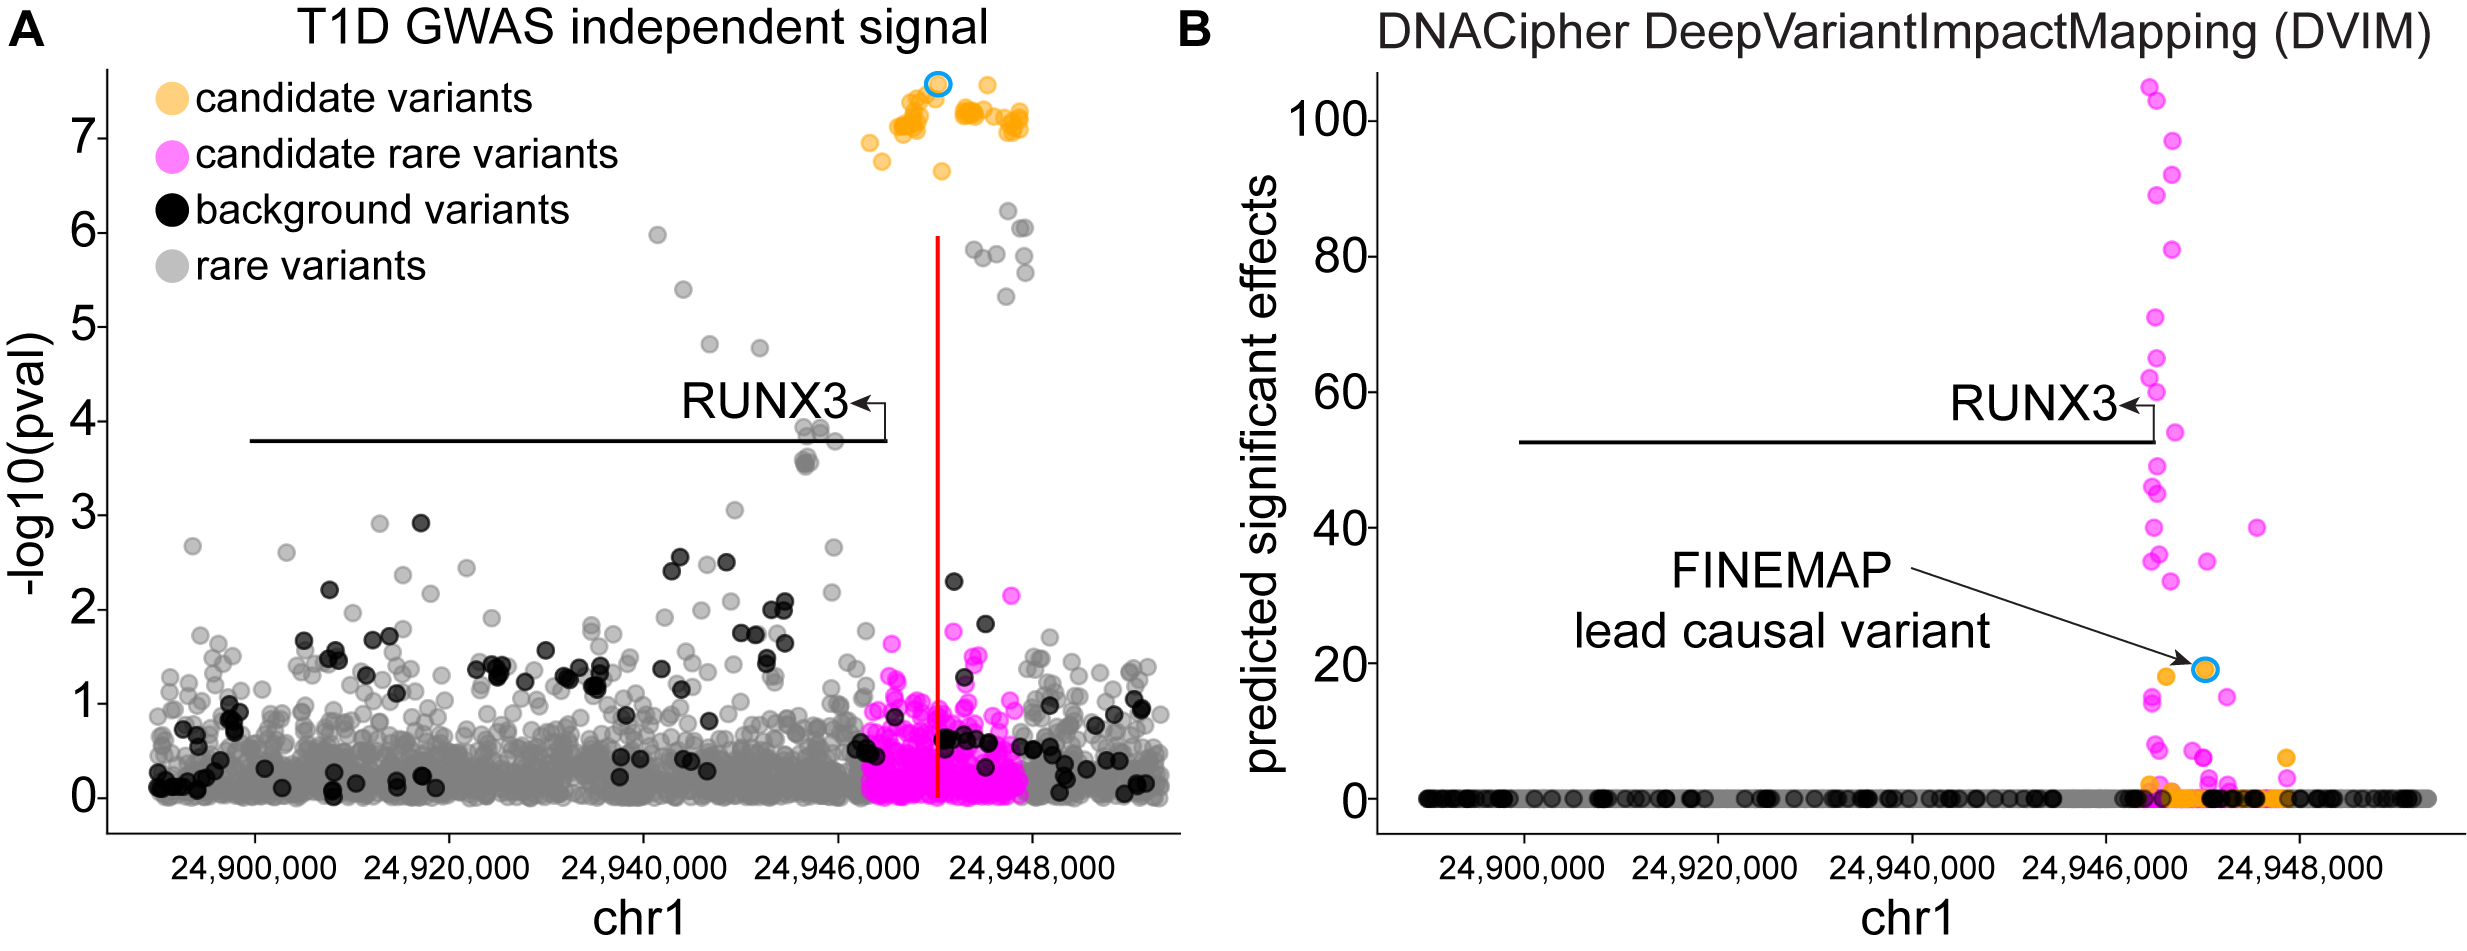

# Compute resources

This notebook can be run on a free T4 GPU, using at most ~4.3Gb of RAM, which can be lowered by adjusting the batch_size parameter.

All times and outputs shown below are for the T4 GPU.

Also tested A100 GPU, which does speed up the below significantly.

CPU and TPU works fine, but is slow & not recommended.

# Installing dependencies

In [ ]:
!python --version

Python 3.11.12


In [ ]:
!pip install pyfaidx kipoiseq pybedtools

In [ ]:
!pip install lightning

In [ ]:
!pip install enformer-pytorch

In [ ]:
!apt-get install bedtools # Alternative installations if you have conda, is: conda install bioconda::bedtools

In [ ]:
#### Installing the dnacipher github
!rm -rf DNACipher
!git clone https://github.com/BradBalderson/DNACipher.git

# Environment Setup

In [ ]:
import os, sys

# Setting this, so that below if component not implemented in Pytorch can fall back to CPU.
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'

# Adding DNACipher to the path
sys.path.append('DNACipher')

In [ ]:
##### Importing dependencies
import torch

import pickle
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sb

import importlib as imp

import pyfaidx

In [ ]:
# DNACipher import
import dnacipher.dna_cipher_infer as dnaci
import dnacipher.dna_cipher_model as dnacm
import dnacipher.dna_cipher_plotting as dnapl
import dnacipher.deep_variant_impact_mapping as dvim

In [ ]:
import importlib as imp
imp.reload(dnacm)
imp.reload(dnaci)
imp.reload(dnapl)
imp.reload(dnaci.pybedtools)
imp.reload(dvim)

<module 'dnacipher.deep_variant_impact_mapping' from '/content/DNACipher/dnacipher/deep_variant_impact_mapping.py'>

In [ ]:
#### Paths
model_path = 'DNACipher/dnacipher/weights/'
weights_path = f'{model_path}TRAINING_DNACV5_MID-AVG-GENOME_ORIG-ALLOC_ENFORMER0_FINETUNE_STRATMSE_model_weights.pth'
sample_file_path = f'{model_path}encode_meta_encode_imputable_filter-fixed_train-test_samp-probs.tsv'

data_path = 'DNACipher/tutorials/data/'
fasta_file_path = f'{data_path}genome.fa'
gtf_file_path = f'{data_path}gencode.v26.annotation.gtf'
gwas_signal_path = f"{data_path}Chiou-2021-T1D-GWAS_RUNX3-signal_variant_stats.txt.gz"

## Detecting TPU or GPU for Pytorch

In [ ]:
try:
    import torch_xla
    import torch_xla.core.xla_model as xm
    device = xm.xla_device()
    print("Using TPU")

except:

  if torch.cuda.is_available():
      device = 'cuda:0'
      print("Will use cuda GPU")

  elif torch.backends.mps.is_available():
      # device = 'mps:0' # Currently cannot make long-sequence inference with mps:0 due to this:
      # print("Will use apple metal GPU")
      # https://github.com/pytorch/pytorch/issues/134416
      # Should be fixed in future version
      device = 'cpu'
      print('Using CPU, mps available but currently not working for long-sequence inference.')

  else:
      device = 'cpu'
      print("No apparent GPU available, using CPU (will be slow).")

device

Will use cuda GPU


'cuda:0'

# Data setup

## Downloading reference genome to load sequences from

Download and index the reference genome fasta file

Credit to Genome Reference Consortium: https://www.ncbi.nlm.nih.gov/grc

Schneider et al 2017 http://dx.doi.org/10.1101/gr.213611.116: Evaluation of GRCh38 and de novo haploid genome assemblies demonstrates the enduring quality of the reference assembly

In [ ]:
!mkdir -p {data_path}
!wget -O - http://hgdownload.cse.ucsc.edu/goldenPath/hg38/bigZips/hg38.fa.gz | gunzip -c > {fasta_file_path}
pyfaidx.Faidx(fasta_file_path)
!ls {data_path}

## Downloading Gencode gene annotations for visualization

In [ ]:
!wget -O - https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_26/gencode.v26.annotation.gtf.gz | gunzip -c > {gtf_file_path}

In [ ]:
#### Loading the gtf
gtf_cols = [
        "chrom", "source", "feature", "start", "end",
        "score", "strand", "frame", "attribute"
    ]
gtf_df = pd.read_csv(gtf_file_path, sep="\t", header=None, comment='#', names=gtf_cols)
gtf_df = gtf_df.loc[gtf_df["feature"].values=='gene', :]
gtf_df['gene_names'] = gtf_df.apply(lambda x: x.iloc[8].split('gene_name')[1].split('; ')[0].strip(' "'), 1)
gtf_df['gene_ids'] = gtf_df.apply(lambda x: x.iloc[8].split('gene_id')[1].split('; ')[0].strip(' "'), 1)
gene_ids = gtf_df['gene_ids'].values

gtf_df.head(3)

,chrom,source,feature,start,end,score,strand,frame,attribute,gene_names,gene_ids
0,chr1,HAVANA,gene,11869,14409,.,+,.,"gene_id ""ENSG00000223972.5""; gene_type ""transc...",DDX11L1,ENSG00000223972.5
12,chr1,HAVANA,gene,14404,29570,.,-,.,"gene_id ""ENSG00000227232.5""; gene_type ""unproc...",WASH7P,ENSG00000227232.5
25,chr1,ENSEMBL,gene,17369,17436,.,-,.,"gene_id ""ENSG00000278267.1""; gene_type ""miRNA""...",MIR6859-1,ENSG00000278267.1


## Loading the pretrained DNACipher model

In [ ]:
# Some extra parameters about the model which cannot be read from the weights:
config = {'activation_function': 'gelu',
          'relu_genome_layer': True, # Is actually gelu, this just means to use activate function for genome layer.
          'layer_norm': True,
          'n_token_features': 3072,
          'relu_output': True,
          'epi_summarise_method': 'flatten',
         }

In [ ]:
dnacipher = dnaci.DNACipher(weight_path=weights_path, sample_file=sample_file_path, config=config,
                            genome_file=fasta_file_path,
                            device=device
                           )

In [ ]:
dnacipher.model_.device

device(type='cuda', index=0)

In [ ]:
### The attached model
dnacipher.model_

DNACipherModel(
  (celltype_embedding): Embedding(191, 128)
  (assay_embedding): Embedding(202, 256)
  (genome_layer): Linear(in_features=3072, out_features=128, bias=True)
  (dense_layers): ModuleList(
    (0-2): 3 x Sequential(
      (0): Linear(in_features=512, out_features=512, bias=True)
      (1): LayerNorm((512,), eps=1e-05, elementwise_affine=False)
    )
  )
  (output_layer): Linear(in_features=512, out_features=1, bias=True)
  (drop): Dropout(p=0.1, inplace=False)
  (loss_function): MSELoss()
)

In [ ]:
### Also Enformer, used to generate the sequence embeddings (3072 sequence embedding input)
dnacipher.transformer_model.device

device(type='cuda', index=0)

In [ ]:
### The cell types / tissues represented
pd.DataFrame( dnacipher.celltypes )

,0
0,A549
1,A673
2,ACC112
3,AG04450
4,B cell
...,...
186,upper lobe of left lung
187,upper lobe of right lung
188,urinary bladder
189,uterus


In [ ]:
### The assays represented:
pd.DataFrame( dnacipher.assays )

,0
0,AFF4_ChIP-seq
1,ARID3A_ChIP-seq
2,ARNT_ChIP-seq
3,ASH2L_ChIP-seq
4,ATAC-seq
...,...
197,minus strand total RNA-seq
198,plus strand polyA minus RNA-seq
199,plus strand polyA plus RNA-seq
200,plus strand total RNA-seq


# Deep Variant Impact Mapping of the RUNX3 T1D locus

Predicting if, where, and what effect of genetic variants.

In [ ]:
# Fine-mapping variants surrounding RUNX3 locus
gene_ = 'RUNX3'
gene_entry = gtf_df.loc[gtf_df['gene_names'].values == gene_, :]
gene_range = list(gene_entry[["chrom","start","end","strand"]].values[0,:])
tss = gene_range[1] if gene_range[3]=="+" else gene_range[2] # Taking start position depending on strand
gene_midpoint = np.mean(gene_range[1:3])

gene_range, tss, gene_midpoint

(['chr1', 24899511, 24965121, '-'], 24965121, np.float64(24932316.0))

Defining a range to take variants from the file, downloaded from the Chiou paper to here (See Supp. Table 3 which lists the fine-mapped variant).

In [ ]:
var_pos = 24970252
locus_midpoint = var_pos
variants_range = (locus_midpoint-round(dnacipher.seq_pred_range*.7), locus_midpoint+round(dnacipher.seq_pred_range*.2))
variants_range

(24889970, 24993190)

## NOTE on how I retrieved the T1D GWAS variant information for the RUNX3 locus:

This is how I downloaded the GWAS variant data for the RUNX3 locus:

Need to use the harmonize version for the meta analysis from here:

    https://ftp.ebi.ac.uk/pub/databases/gwas/summary_statistics/GCST90014001-GCST90015000/GCST90014023/harmonised/

Then isolated the variants on chromosome 1, which is where RUNX3 is located.

    (NOTE on unix command-line)
    gzip -d -c 34012112-GCST90014023-EFO_0001359-Build38.f.tsv.gz | awk 'NR==1 || $3 == 1' | gzip -c > 34012112-GCST90014023-EFO_0001359-Build38.f.tsv.chr1.gz
    
Then I read-in the variants on chr1, and subsetted to those at the range defined above for the RUNX3 T1D locus:

(NOTE this is Python)
    
    chr_gwas_stats = pd.read_csv(f"34012112-GCST90014023-EFO_0001359-Build38.f.tsv.{gene_range[0]}.gz", sep='\t')
    
    gene_gwas_variants_bool = np.logical_and(chr_gwas_stats['base_pair_location'].values > variants_range[0],
                                         chr_gwas_stats['base_pair_location'].values < variants_range[1])

    locus_gwas_stats = chr_gwas_stats.loc[gene_gwas_variants_bool, :].copy()
    locus_gwas_stats['-log10_pval'] = -np.log10( locus_gwas_stats['p_value'].values )
    locus_gwas_stats = locus_gwas_stats.iloc[ np.argsort(locus_gwas_stats['base_pair_location'].values), :]

## Loading the variants at this locus that are already saved in the github repo

In [ ]:
locus_gwas_stats = pd.read_csv(gwas_signal_path, sep='\t')
locus_gwas_stats.head(3)

,variant_id,p_value,chromosome,base_pair_location,effect_allele,other_allele,effect_allele_frequency,beta,standard_error,odds_ratio,ci_lower,ci_upper,-log10_pval
0,rs6657823,0.774,1,24890003,G,A,0.138000,0.005930,0.020636,NaN,NaN,NaN,0.111259
1,rs6663476,0.539,1,24890041,C,T,0.831000,-0.012048,0.019613,NaN,NaN,NaN,0.268411
2,rs775624316,0.137,1,24890042,A,G,0.000469,0.704536,0.473859,NaN,NaN,NaN,0.863279


## Stratifying the variants as candidate common and rare variants, background variants, and other variants.

Performing stratification of variants at GWAS loci to categories:

    * 'candidate' variants (common significant variants)
    * 'rare' variants (non-significant rare variants in the same region as the candidate variants)
    * 'background' variants (common non-significant variants)
    * 'other' variants (rare variants outside of the hit locus).

In [ ]:
#### This code addds the column 'var_label' to each varaint according to the above labels.
stratified_gwas_stats = dvim.stratify_variants(locus_gwas_stats)
stratified_gwas_stats.head(3)

No. other variants: 1841
Total selected varaints 543 / 2538
	No. candidate variants: 49
	No. rare variants: 359
	No. background variants: 135


,variant_id,p_value,chromosome,base_pair_location,effect_allele,other_allele,effect_allele_frequency,beta,standard_error,odds_ratio,ci_lower,ci_upper,-log10_pval,var_label
0,rs72657048,1.110000e-07,1,24963243,G,C,0.509,0.074632,0.014060,NaN,NaN,NaN,6.954677,candidate
1,rs6672420,1.740000e-07,1,24964519,T,A,0.483,0.073690,0.014103,NaN,NaN,NaN,6.759451,candidate
2,rs7528484,7.480000e-08,1,24966177,T,C,0.510,0.075321,0.014002,NaN,NaN,NaN,7.126098,candidate


## Plotting the stratification results

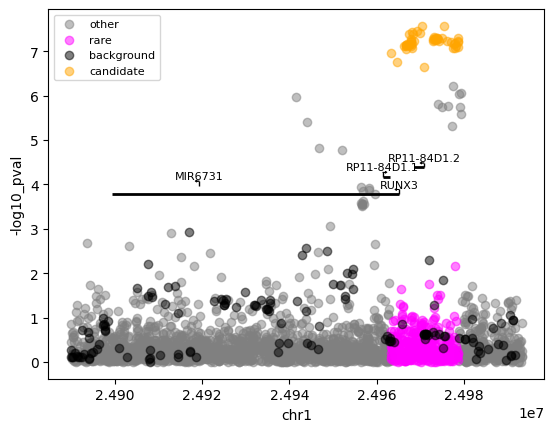

In [ ]:
variant_colors = {'other': 'grey', 'candidate': 'orange', 'background': 'black', 'rare': 'magenta'}

dnapl.plot_variant_stats(stratified_gwas_stats, "-log10_pval", "var_label",
                         color_dict=variant_colors, gtf_df=gtf_df)

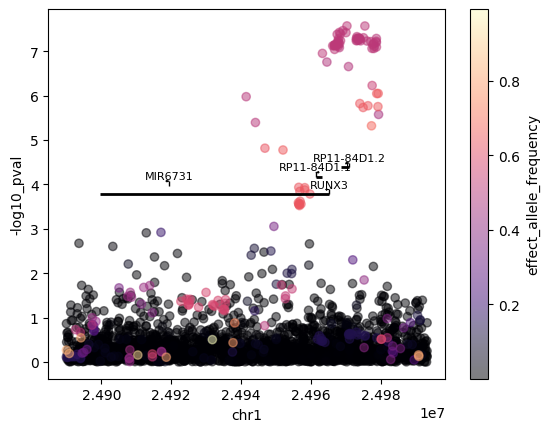

In [ ]:
#### Can verify the stratifications by plotting the minor allele frequency!
dnapl.plot_variant_stats(stratified_gwas_stats, "-log10_pval", "effect_allele_frequency",
                         color_dict=variant_colors, gtf_df=gtf_df)

# Running DNACipher variant effect prediction

Setting the sequence position that will be used to centre all query sequences through DNACipher regardless of variant location, so that when scoring the effect we are comparing apples-to-apples between variants.

In [ ]:
# Subsetting to just the variants we want to query:
selected_gwas_stats = stratified_gwas_stats.loc[stratified_gwas_stats['var_label'].values!='other'].copy()

### Need to re-arrange the column order in order to satisfy DNACipher variant effect inference input!
new_col_order = ['chromosome', 'base_pair_location', 'other_allele', 'effect_allele']
new_col_order.extend([col for col in selected_gwas_stats.columns if col not in new_col_order])

selected_gwas_stats = selected_gwas_stats.loc[:, new_col_order]
selected_gwas_stats['chromosome'] = [f"chr{chr_}" for chr_ in selected_gwas_stats['chromosome']]

selected_gwas_stats.head(3)

,chromosome,base_pair_location,other_allele,effect_allele,variant_id,p_value,effect_allele_frequency,beta,standard_error,odds_ratio,ci_lower,ci_upper,-log10_pval,var_label
0,chr1,24963243,C,G,rs72657048,1.110000e-07,0.509,0.074632,0.014060,NaN,NaN,NaN,6.954677,candidate
1,chr1,24964519,A,T,rs6672420,1.740000e-07,0.483,0.073690,0.014103,NaN,NaN,NaN,6.759451,candidate
2,chr1,24966177,C,T,rs7528484,7.480000e-08,0.510,0.075321,0.014002,NaN,NaN,NaN,7.126098,candidate


In [ ]:
##### Setting where we want to position the query sequence for each variant, so is consistent across all variants to compare
selected_gwas_stats['seq_pos'] = locus_midpoint

Selecting the contexts to make predictions for!

In [ ]:
celltypes_to_infer = list(set(['peripheral blood mononuclear cell', 'natural killer cell', 'natural killer cell',
                             'naive thymus-derived CD8-positive, alpha-beta T cell',
                             'naive thymus-derived CD4-positive, alpha-beta T cell',
                             'pancreas', 'effector memory CD8-positive, alpha-beta T cell',
                             'effector memory CD4-positive, alpha-beta T cell',
                             'central memory CD8-positive, alpha-beta T cell',
                             'body of pancreas', 'activated naive CD8-positive, alpha-beta T cell',
                             'T-helper 17 cell', 'T-cell',  'CD14-positive monocyte',
                             'CD4-positive, CD25-positive, alpha-beta regulatory T cell',
                             'CD4-positive, alpha-beta T cell', 'CD4-positive, alpha-beta memory T cell',
                             'CD8-positive, alpha-beta T cell', 'CD8-positive, alpha-beta memory T cell']))

assays_to_infer = [assay for assay in dnacipher.assays if not ('minus strand' in assay or 'ChIP-seq' in assay)]
assays_to_infer

[np.str_('ATAC-seq'),
 np.str_('DNase-seq'),
 np.str_('plus strand polyA minus RNA-seq'),
 np.str_('plus strand polyA plus RNA-seq'),
 np.str_('plus strand total RNA-seq'),
 np.str_('signal of polyA plus RNA-seq')]

In [ ]:
#### Total effects to infer:
total_expers_to_infer = len(celltypes_to_infer) * len(assays_to_infer)
print(f"Inferring effects for {total_expers_to_infer} experiments out of {len(dnacipher.celltypes)*len(dnacipher.assays)} represented.")

Inferring effects for 108 experiments out of 38582 represented.


In [ ]:
#### Total effects to infer:
print("Total number of effects to infer across variants:", (selected_gwas_stats.shape[0] * total_expers_to_infer)/(10**3), "thousand")

Total number of effects to infer across variants: 58.644 thousand


### RUNNING the variant effect inference with DNACipher

NOTE that because there are 543 variants to infer and 108 contexts, can REDUCE the no. of contexts or variants to reduce computational time.

Alternatively, could use a beefier GPU. On an A40, the below runs in ~5min.

In [ ]:
?dnacipher.infer_multivariant_effects

In [ ]:
selected_pred_effects = dnacipher.infer_multivariant_effects(selected_gwas_stats,
                                                             celltypes_to_infer, assays_to_infer,
                                                     seq_pos_col='seq_pos', # Defines how to centre the query sequences.
                                                     verbose=True,
                                                     batch_size=108, #Sam size as no. of experiments to infer
                                                     # 1-based indexing of variants, if doesn't find expected all allele will throw error
                                                     index_base=1,
                                                    )

PROCESSED 0/543 variants in 0.043mins
PROCESSED 55/543 variants in 2.289mins
PROCESSED 110/543 variants in 4.512mins
PROCESSED 165/543 variants in 6.728mins
PROCESSED 220/543 variants in 8.958mins
PROCESSED 275/543 variants in 11.176mins
PROCESSED 330/543 variants in 13.381mins
PROCESSED 385/543 variants in 15.591mins
PROCESSED 440/543 variants in 17.801mins
PROCESSED 495/543 variants in 20.008mins
PROCESSED 543/543 variants.


In [ ]:
selected_pred_effects.head(3)

,natural killer cell---ATAC-seq,natural killer cell---DNase-seq,natural killer cell---plus strand polyA minus RNA-seq,natural killer cell---plus strand polyA plus RNA-seq,natural killer cell---plus strand total RNA-seq,natural killer cell---signal of polyA plus RNA-seq,"naive thymus-derived CD4-positive, alpha-beta T cell---ATAC-seq","naive thymus-derived CD4-positive, alpha-beta T cell---DNase-seq","naive thymus-derived CD4-positive, alpha-beta T cell---plus strand polyA minus RNA-seq","naive thymus-derived CD4-positive, alpha-beta T cell---plus strand polyA plus RNA-seq",...,"central memory CD8-positive, alpha-beta T cell---plus strand polyA minus RNA-seq","central memory CD8-positive, alpha-beta T cell---plus strand polyA plus RNA-seq","central memory CD8-positive, alpha-beta T cell---plus strand total RNA-seq","central memory CD8-positive, alpha-beta T cell---signal of polyA plus RNA-seq",T-cell---ATAC-seq,T-cell---DNase-seq,T-cell---plus strand polyA minus RNA-seq,T-cell---plus strand polyA plus RNA-seq,T-cell---plus strand total RNA-seq,T-cell---signal of polyA plus RNA-seq
0,-0.130487,-0.253485,-0.353393,-0.340903,-0.281509,-0.452060,-0.153389,-0.205462,0.369036,0.333374,...,-0.058066,-0.127776,-0.084454,-0.213356,-0.195417,-0.395821,0.303629,0.333257,0.321494,-0.509819
1,-0.900998,-1.649776,-3.080156,-2.747344,-2.516152,-3.959513,-0.955449,-1.208428,-3.160297,3.354201,...,-0.359546,-0.940234,-0.733329,-1.805942,1.186232,-2.047332,-2.674963,3.257060,3.183187,-6.143505
2,-3.384765,-4.674168,-4.061858,-4.133465,-3.131186,-3.069555,-2.660544,2.471774,3.566003,4.335052,...,-0.623898,-1.416211,-0.937075,-1.949609,4.190684,5.156841,-3.058751,-4.128591,-3.237635,-3.163383


# Calculating p-values per molecular effect

Calls variants with significant effect ABOVE non-significant background variants.

In [ ]:
?dvim.calc_variant_effect_pvals

In [ ]:
boot_pvals_df, boot_counts_df = dvim.calc_variant_effect_pvals(selected_gwas_stats, selected_pred_effects,
                                                                                  n_boots=10_000, verbosity=1)

Loading input files.
Separating into background and candidate / rare variants.
Finished boot-strapping for 0 / 10000 (0.0%) in 0.1mins
Finished boot-strapping for 1000 / 10000 (10.0%) in 0.1mins
Finished boot-strapping for 2000 / 10000 (20.0%) in 0.1mins
Finished boot-strapping for 3000 / 10000 (30.0%) in 0.1mins
Finished boot-strapping for 4000 / 10000 (40.0%) in 0.1mins
Finished boot-strapping for 5000 / 10000 (50.0%) in 0.1mins
Finished boot-strapping for 6000 / 10000 (60.0%) in 0.1mins
Finished boot-strapping for 7000 / 10000 (70.0%) in 0.1mins
Finished boot-strapping for 8000 / 10000 (80.0%) in 0.1mins
Finished boot-strapping for 9000 / 10000 (90.0%) in 0.1mins
Finished boot-strapping.

Found 1505 significant effects.
	Total vars with significant effects: 42
	Mean significant effects per significant variant: 35.833333333333336

DONE!


In [ ]:
boot_counts_df.shape

(543, 108)

In [ ]:
boot_counts_df.head(2)

,natural killer cell---ATAC-seq,natural killer cell---DNase-seq,natural killer cell---plus strand polyA minus RNA-seq,natural killer cell---plus strand polyA plus RNA-seq,natural killer cell---plus strand total RNA-seq,natural killer cell---signal of polyA plus RNA-seq,"naive thymus-derived CD4-positive, alpha-beta T cell---ATAC-seq","naive thymus-derived CD4-positive, alpha-beta T cell---DNase-seq","naive thymus-derived CD4-positive, alpha-beta T cell---plus strand polyA minus RNA-seq","naive thymus-derived CD4-positive, alpha-beta T cell---plus strand polyA plus RNA-seq",...,"central memory CD8-positive, alpha-beta T cell---plus strand polyA minus RNA-seq","central memory CD8-positive, alpha-beta T cell---plus strand polyA plus RNA-seq","central memory CD8-positive, alpha-beta T cell---plus strand total RNA-seq","central memory CD8-positive, alpha-beta T cell---signal of polyA plus RNA-seq",T-cell---ATAC-seq,T-cell---DNase-seq,T-cell---plus strand polyA minus RNA-seq,T-cell---plus strand polyA plus RNA-seq,T-cell---plus strand total RNA-seq,T-cell---signal of polyA plus RNA-seq
0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,...,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0
1,9998.0,9998.0,6296.0,9330.0,7446.0,7664.0,10000.0,10000.0,9588.0,9833.0,...,9521.0,9824.0,6302.0,7064.0,10000.0,10000.0,9222.0,9371.0,5863.0,5129.0


In [ ]:
# NOTE that these are ALREADY Bonferroni corrected!!!!
boot_pvals_df.head(3)

,natural killer cell---ATAC-seq,natural killer cell---DNase-seq,natural killer cell---plus strand polyA minus RNA-seq,natural killer cell---plus strand polyA plus RNA-seq,natural killer cell---plus strand total RNA-seq,natural killer cell---signal of polyA plus RNA-seq,"naive thymus-derived CD4-positive, alpha-beta T cell---ATAC-seq","naive thymus-derived CD4-positive, alpha-beta T cell---DNase-seq","naive thymus-derived CD4-positive, alpha-beta T cell---plus strand polyA minus RNA-seq","naive thymus-derived CD4-positive, alpha-beta T cell---plus strand polyA plus RNA-seq",...,"central memory CD8-positive, alpha-beta T cell---plus strand polyA minus RNA-seq","central memory CD8-positive, alpha-beta T cell---plus strand polyA plus RNA-seq","central memory CD8-positive, alpha-beta T cell---plus strand total RNA-seq","central memory CD8-positive, alpha-beta T cell---signal of polyA plus RNA-seq",T-cell---ATAC-seq,T-cell---DNase-seq,T-cell---plus strand polyA minus RNA-seq,T-cell---plus strand polyA plus RNA-seq,T-cell---plus strand total RNA-seq,T-cell---signal of polyA plus RNA-seq
0,1.0000,1.0000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.0000,1.000000,1.000000,1.000000,1.000000,1.000000
1,0.9998,0.9998,0.629637,0.933007,0.744626,0.766423,1.000000,1.000000,0.958804,0.983302,...,0.952105,0.982402,0.630237,0.706429,1.0000,1.000000,0.922208,0.937106,0.586341,0.512949
2,0.0001,0.0001,0.039296,0.165483,0.195280,0.989901,0.007099,0.708229,0.795720,0.621038,...,0.000100,0.093091,0.021098,0.449355,0.0001,0.136186,0.683132,0.408159,0.528347,0.999900


# Calling significant effects

In [ ]:
sig_effects, foldchange_effects = dvim.call_sig_effects(selected_gwas_stats, selected_pred_effects, boot_pvals_df, fc_cutoff=2)

In [ ]:
sig_effects.head(2)

,natural killer cell---ATAC-seq,natural killer cell---DNase-seq,natural killer cell---plus strand polyA minus RNA-seq,natural killer cell---plus strand polyA plus RNA-seq,natural killer cell---plus strand total RNA-seq,natural killer cell---signal of polyA plus RNA-seq,"naive thymus-derived CD4-positive, alpha-beta T cell---ATAC-seq","naive thymus-derived CD4-positive, alpha-beta T cell---DNase-seq","naive thymus-derived CD4-positive, alpha-beta T cell---plus strand polyA minus RNA-seq","naive thymus-derived CD4-positive, alpha-beta T cell---plus strand polyA plus RNA-seq",...,"central memory CD8-positive, alpha-beta T cell---plus strand polyA minus RNA-seq","central memory CD8-positive, alpha-beta T cell---plus strand polyA plus RNA-seq","central memory CD8-positive, alpha-beta T cell---plus strand total RNA-seq","central memory CD8-positive, alpha-beta T cell---signal of polyA plus RNA-seq",T-cell---ATAC-seq,T-cell---DNase-seq,T-cell---plus strand polyA minus RNA-seq,T-cell---plus strand polyA plus RNA-seq,T-cell---plus strand total RNA-seq,T-cell---signal of polyA plus RNA-seq
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
foldchange_effects.head(2)

,natural killer cell---ATAC-seq,natural killer cell---DNase-seq,natural killer cell---plus strand polyA minus RNA-seq,natural killer cell---plus strand polyA plus RNA-seq,natural killer cell---plus strand total RNA-seq,natural killer cell---signal of polyA plus RNA-seq,"naive thymus-derived CD4-positive, alpha-beta T cell---ATAC-seq","naive thymus-derived CD4-positive, alpha-beta T cell---DNase-seq","naive thymus-derived CD4-positive, alpha-beta T cell---plus strand polyA minus RNA-seq","naive thymus-derived CD4-positive, alpha-beta T cell---plus strand polyA plus RNA-seq",...,"central memory CD8-positive, alpha-beta T cell---plus strand polyA minus RNA-seq","central memory CD8-positive, alpha-beta T cell---plus strand polyA plus RNA-seq","central memory CD8-positive, alpha-beta T cell---plus strand total RNA-seq","central memory CD8-positive, alpha-beta T cell---signal of polyA plus RNA-seq",T-cell---ATAC-seq,T-cell---DNase-seq,T-cell---plus strand polyA minus RNA-seq,T-cell---plus strand polyA plus RNA-seq,T-cell---plus strand total RNA-seq,T-cell---signal of polyA plus RNA-seq
0,-0.165515,-0.324673,-0.377171,-0.370812,-0.313318,-0.496536,-0.160154,-0.152552,0.592591,0.485746,...,-0.047161,-0.096018,-0.058915,-0.233319,-0.240089,-0.490544,0.447943,0.505072,0.493472,-0.422707
1,-0.936026,-1.720963,-3.103934,-2.777253,-2.547960,-4.003989,-0.962214,-1.155518,-2.936742,3.506573,...,-0.348640,-0.908476,-0.707790,-1.825905,1.141559,-2.142055,-2.530649,3.428875,3.355165,-6.056393


As mentioned in the manuscript, we generally observe that rare variants have much higher and more significant predicted molecular effects! See Volcano plot below.

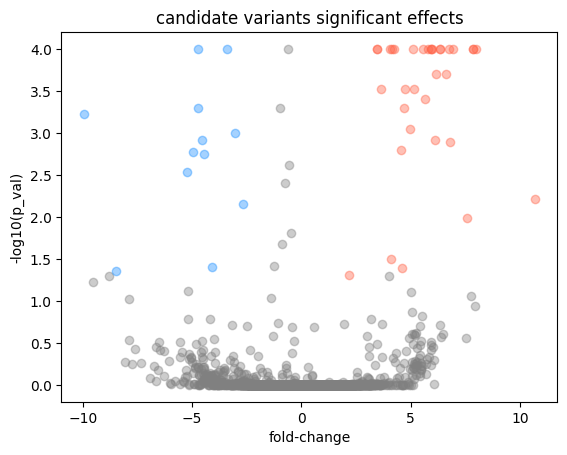

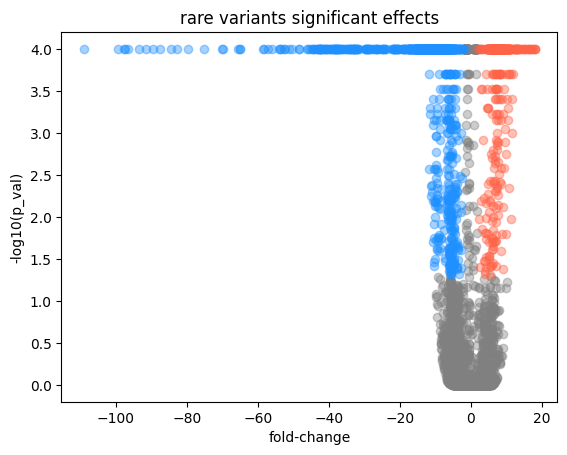

In [ ]:
dnapl.plot_volcano('candidate', selected_gwas_stats, sig_effects, foldchange_effects, boot_pvals_df)
dnapl.plot_volcano('rare', selected_gwas_stats, sig_effects, foldchange_effects, boot_pvals_df)

# Visualiing the Impact Mapping at the locus

In [ ]:
#### In this case, take as s
n_sig_effects = (sig_effects).sum(axis=1)
n_sig_effects.shape

(543,)

In [ ]:
selected_gwas_stats['n_sig_effects'] = n_sig_effects.values
selected_gwas_stats['n_sig_effects'].dtype

dtype('int64')

In [ ]:
# The top impact variants, rs10751776 at position chr1:24970252 is the highest FINEMAP variant at this locus
selected_gwas_stats.loc[n_sig_effects>5,:].head(5)

,chromosome,base_pair_location,other_allele,effect_allele,variant_id,p_value,effect_allele_frequency,beta,standard_error,odds_ratio,ci_lower,ci_upper,-log10_pval,var_label,seq_pos,n_sig_effects
2,chr1,24966177,C,T,rs7528484,7.480000e-08,0.510000,0.075321,0.014002,NaN,NaN,NaN,7.126098,candidate,24970252,18
23,chr1,24970252,A,C,rs10751776,2.670000e-08,0.510000,0.078145,0.014050,NaN,NaN,NaN,7.573489,candidate,24970252,19
45,chr1,24978623,T,C,rs6600247,5.910000e-08,0.508000,0.076164,0.014048,NaN,NaN,NaN,7.228413,candidate,24970252,6
81,chr1,24964466,G,A,rs548250481,2.610000e-01,0.001290,0.745023,0.663360,NaN,NaN,NaN,0.583359,rare,24970252,61
82,chr1,24964514,C,T,rs200345680,3.550000e-01,0.000064,1.612349,1.744282,NaN,NaN,NaN,0.449772,rare,24970252,105


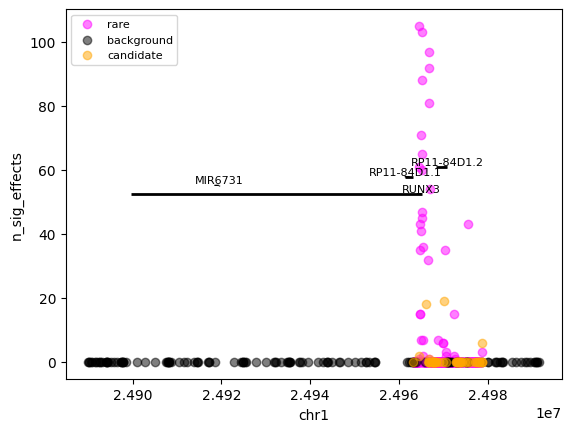

In [ ]:
dnapl.plot_variant_stats(selected_gwas_stats, "n_sig_effects", "var_label",
                         color_dict=variant_colors, gtf_df=gtf_df)

To do this across many different loci, recommend using the commandline interface so can run many loci in parallel more easily. Albeit you will need multiple GPU to run the DNACipher inference steps in parallel.